AJ Benjamin
# Binary Classification Using Logistic Regression:

Moving beyond linear models and into nonlinear models opens up the possibility to analyze more complex patterns and create things such as binary classifiers. Classification models have many applications, from fraud and spam detection, to image detection and medical diagnosis. In this case we will be creating a logistic regression based classification system that analyzes breast cancer data and fits an instance into two cases: malignant, or nonbenign. 


Logistic regression works by combigning several mathmatical concepts.

First, is the linear model. h(x₁,x₂,...,xₖ)=β₀+β₁x₁+β₂x₂+...+βₖxₖ. This model represents the line of best fit through a data set with many different variables.

This linear model is then used as the input($z$) to the sigmoid function. $\sigma(z) = \frac{1}{1 + e^{-z}}$.To become $h_{\theta}(x)=\sigma (\theta ^T x)= \frac{1}{1+e^{-\theta ^T x}}$, where $\theta$ is the vector of coefficients and $x$ is the vector of inputs. This function compresses the output into values between 0 and 1 which can then be split into two classes with a decision threshold of 0.5. 

The error optimized with the log loss function $J(\theta)=-(ylog h_{\theta}x)+(1-y)log(1-h_{\theta}(x)))$

In [37]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

dataset = load_breast_cancer(as_frame=True)
# Create a DataFrame
df = pd.DataFrame(dataset.data, columns=dataset.feature_names)
df['target'] = dataset.target

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [38]:
dataset['data'].head()


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [39]:
# Check for missing values
print(df.isnull().sum())

# Summary statistics
print(df.describe())

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64
       mean radius  mean texture  mean perimeter    mean area  \
count   569.000000    5

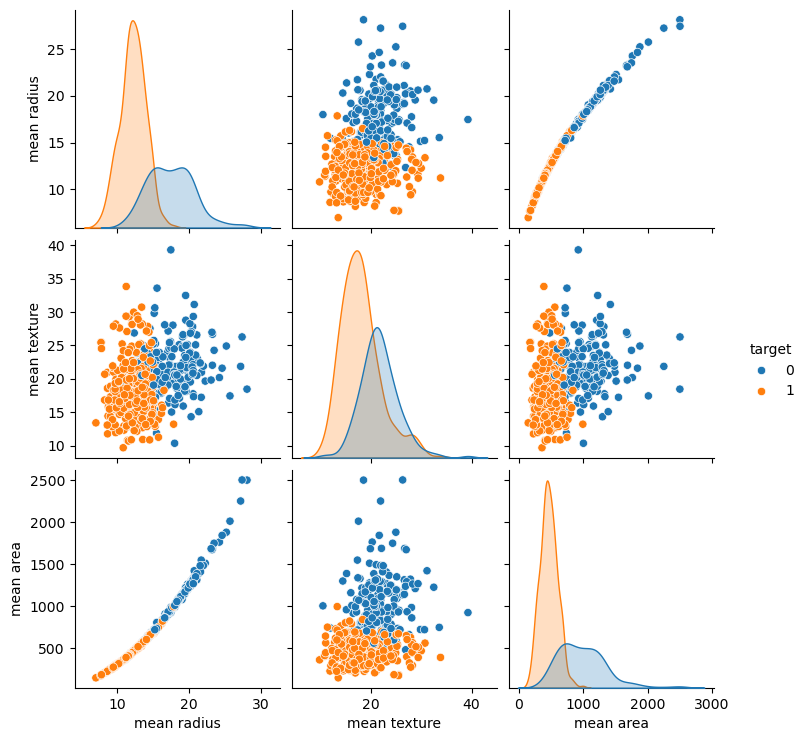

In [47]:
# Pairplot of the dataset
sns.pairplot(df, vars=['mean radius', 'mean texture', 'mean area'], hue='target')
plt.show()

In [40]:
dataset['target'].head()

0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int32

In [41]:
dataset['target'].value_counts()

target
1    357
0    212
Name: count, dtype: int64

In [42]:
X = dataset['data']
y = dataset['target']

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y , test_size=0.25, random_state=0)

In [43]:
from sklearn.preprocessing import StandardScaler

ss_train = StandardScaler()
X_train = ss_train.fit_transform(X_train)

ss_test = StandardScaler()
X_test = ss_test.fit_transform(X_test)

In [44]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(X_train, y_train)
# Display the coefficients
print('Intercept:', model.intercept_)
print('Coefficients:', model.coef_)

Intercept: [0.02651424]
Coefficients: [[-0.31167303 -0.58082201 -0.32131835 -0.38161278 -0.11923966  0.43130513
  -0.70867977 -0.85378868 -0.46682033  0.11842553 -1.384584    0.08915178
  -0.95504656 -0.93809826  0.18173417  0.99841869  0.1098606  -0.34148205
   0.20112256  0.80467192 -0.91482867 -0.91731629 -0.81023153 -0.85401188
  -0.45736929  0.11351219 -0.8359122  -0.98702282 -0.59104801 -0.62212143]]


In [32]:
predictions = model.predict(X_test)


In [45]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, predictions)

TN, FP, FN, TP = confusion_matrix(y_test, predictions).ravel()

print('True Positive(TP)  = ', TP)
print('False Positive(FP) = ', FP)
print('True Negative(TN)  = ', TN)
print('False Negative(FN) = ', FN)

True Positive(TP)  =  86
False Positive(FP) =  2
True Negative(TN)  =  51
False Negative(FN) =  4


In [46]:
accuracy =  (TP + TN) / (TP + FP + TN + FN)

print('Accuracy of the binary classifier = {:0.3f}'.format(accuracy))

Accuracy of the binary classifier = 0.958


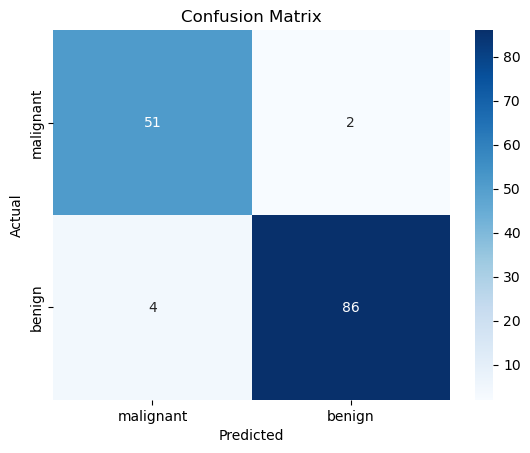

In [30]:
# Plot the confusion matrix
# Calculate confusion matrix
conf_matrix = confusion_matrix(y_test, predictions)

sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=dataset.target_names, yticklabels=dataset.target_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()


In [ ]:
Sources:

https://www.statology.org/step-by-step-guide-to-logistic-regression-in-python/
https://www.learndatasci.com/glossary/binary-classification/
https://www.geeksforgeeks.org/machine-learning/ml-logistic-regression-using-python/
https://gogradientdescent.com/the-sigmoid-function-a-key-pillar-in-machine-learning/
https://www.datacamp.com/tutorial/sigmoid-function
https://www.youtube.com/watch?v=vN5cNN2-HWE
